# Do uncertain GPM nodes benefit from more random walks?

This notebook explains and reproduces the core diagnostic using **your saved Computers predictions**. No model is trained, no new inference is run, and no adaptive algorithm is implemented.

**The idea:** if a node's prediction changes substantially when we resample its walks at K=16, perhaps giving that node more walks will help. But it could simply be a difficult node that stays wrong. This experiment separates those possibilities.

**What we found for this checkpoint:** uncertainty has a positive association with benefit. Giving extra samples to the most uncertain quarter of nodes works better than giving them to a random quarter. That supports a next experiment, but it does **not** establish an efficient adaptive system.

## Where is the code?

You are in the project root, beside `experiments.ipynb`.

- **This notebook:** the main calculations are written out below.
- `sampling_benefit_diagnostic/experiment.py`: full analysis, bootstrap intervals, score comparisons and figure generation.
- `sampling_benefit_diagnostic/test_experiment.py`: seven small synthetic tests.
- `sampling_benefit_diagnostic/results/REPORT.md`: detailed report.
- `sampling_experiment_results/computers_sampling_full.npz`: original prediction cache.

The diagnostic folder is beside the inner `GPM/` repository, so it will not appear if your editor has opened only that inner folder.

Run the cells in order. Use a Python environment with NumPy, pandas, SciPy and matplotlib. The notebook reads existing files and does not overwrite the original experiments or results.


In [2]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
from scipy.stats import spearmanr, pearsonr
import matplotlib.pyplot as plt

# Normally Jupyter starts in this notebook's folder. Also tolerate the inner GPM folder.
ROOT = Path.cwd()
if not (ROOT / 'sampling_experiment_results').exists():
    ROOT = ROOT.parent
assert (ROOT / 'sampling_experiment_results').exists(), 'Start Jupyter in uncertainty-estimation-gpm/'
RESULTS = ROOT / 'sampling_benefit_diagnostic' / 'results'
metrics = json.loads((RESULTS / 'metrics.json').read_text())
plt.rcParams.update({'figure.figsize': (8, 4), 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False})
print('Project:', ROOT)


Project: /Users/arvind/Documents/research/experiments/uncertainty-estimation-gpm


## 1. What exactly was saved?

For each K, you ran stochastic inference 50 times on the **same 2,751 evaluation nodes**. Each run supplies a vector of ten class probabilities for every node.

K is the number of sampled random-walk patterns provided to the frozen GPM at inference. Changing K changes the sampled evidence, not the model weights. For a single node, K=16 can produce different predictions on different runs because the walks differ.

The cache already contains probabilities, so we do not apply softmax again. The shared node axis keeps predictions and labels aligned across all budgets and runs.


In [3]:
with np.load(ROOT / 'sampling_experiment_results/computers_sampling_full.npz', allow_pickle=False) as cache:
    P = cache['probabilities'].astype(np.float64)
    labels = cache['labels']
    node_ids = cache['node_ids']
    budgets = cache['k_values']
    checkpoint = str(cache['checkpoint'].item())

assert P.ndim == 4 and P.shape[2] == len(labels) == len(node_ids)
assert len(np.unique(node_ids)) == len(node_ids)
assert np.isfinite(P).all() and np.all((P >= 0) & (P <= 1))
assert np.allclose(P.sum(axis=-1), 1, atol=1e-6, rtol=0)
assert labels.min() >= 0 and labels.max() < P.shape[-1]
k_index = {int(k): j for j, k in enumerate(budgets)}
print('Axes: [budget, repetition, node, class]')
print('Shape:', P.shape)
print('Available K:', budgets.tolist())
print('Checkpoint recorded in cache:', checkpoint)


Axes: [budget, repetition, node, class]
Shape: (6, 50, 2751, 10)
Available K: [4, 8, 16, 32, 64, 128]
Checkpoint recorded in cache: /workspace/GPM/model/computers/epoch_380.pt


**Provenance limit:** the producer script selects the first test split using seed 42 and the tuned Computers preprocessing (including Laplacian positional encodings). The original dataset masks and checkpoint are not present locally, so their identity cannot be independently verified from this cache. These results are conditional on this one recorded checkpoint. K=256 is not in the available cache.

## 2. Why divide the 50 runs into two groups?

We want to ask whether uncertainty predicts benefit on **different runs**, rather than measuring both from the same random fluctuations.

- **A: runs 0–24.** Measure how much each node's K=16 probabilities move around. No labels are needed.
- **B: runs 25–49.** Measure how often the node is wrong at K=16 and K=128, using its label.

This is a split of inference repetitions, not a new train/test split of nodes. All nodes remain the original evaluation nodes.

The producer uses different seeds across K. We compare the same nodes at both budgets, but do not assume that repetition 25 at K=16 uses the same walks as repetition 25 at K=128.


In [4]:
A = np.arange(25)
B = np.arange(25, 50)
assert P.shape[1] == 50
assert not set(A).intersection(B)

p16_A = P[k_index[16], A]
p16_B = P[k_index[16], B]
p128_B = P[k_index[128], B]
print(f'{len(A)} uncertainty runs; {len(B)} separate outcome runs at each endpoint.')


25 uncertainty runs; 25 separate outcome runs at each endpoint.


## 3. What does “sampling uncertainty” mean here?

Take one node. Average its class probabilities across A. Then measure how far each run's probability vector sits from that average.

- If every run gives nearly the same vector, uncertainty is small.
- If different walks make the probabilities move substantially, uncertainty is large.

We sum the variance over all classes. This is the **trace of the sample covariance**, with the usual R−1 denominator. It is sampling variability, not a Bayesian posterior variance.

Notice that **stable does not mean correct**. A model can confidently predict the wrong class in every run.


In [5]:
mean_prob = p16_A.mean(axis=0)
U = ((p16_A - mean_prob) ** 2).sum(axis=(0, 2)) / (len(A) - 1)
# Same calculation, written compactly:
np.testing.assert_allclose(U, p16_A.var(axis=0, ddof=1).sum(axis=-1))
print('One uncertainty score for each of', len(U), 'nodes.')
print('No ground-truth labels were used in this calculation.')


One uncertainty score for each of 2751 nodes.
No ground-truth labels were used in this calculation.


## 4. What does “benefit from more samples” mean?

For each node, count mistakes across B. A node that is wrong in 10 of 25 runs has estimated stochastic error 10/25 = 40%.

**Benefit = error at K=16 − error at K=128.**

For example, an error change from 40% to 20% means +20 percentage points of benefit. This is an illustrative example, not a measured node result. Negative benefit means the higher budget was worse in the observed runs. We keep those negative values.

We average errors over stochastic runs; we do not first average their probabilities and make a single ensemble prediction. Those would answer different questions.


In [6]:
e16 = (p16_B.argmax(axis=-1) != labels).mean(axis=0)
e128 = (p128_B.argmax(axis=-1) != labels).mean(axis=0)
delta = e16 - e128

summary = pd.DataFrame({
    'Measurement': ['Mean error at K=16', 'Mean error at K=128', 'Mean error reduction',
                    'Nodes with positive benefit', 'Nodes with zero estimated benefit', 'Nodes with negative benefit'],
    'Value (%)': 100 * np.array([e16.mean(), e128.mean(), delta.mean(),
                                 (delta > 0).mean(), (delta == 0).mean(), (delta < 0).mean()])
})
display(summary.round(3))
np.testing.assert_allclose(delta.mean(), metrics['means']['delta_error']['estimate'])


,Measurement,Value (%)
0,Mean error at K=16,10.286
1,Mean error at K=128,9.093
2,Mean error reduction,1.192
3,Nodes with positive benefit,13.268
4,Nodes with zero estimated benefit,82.515
5,Nodes with negative benefit,4.217


The overall error reduction is **1.19 percentage points**, not 1.19% relative improvement. About **82.5% of nodes have equal estimated error** at the two endpoints. Many of these are always correct; some are consistently wrong. With only 25 outcome runs, an individual node's estimated error moves in steps of 4 percentage points.

## 5. Experiment A: do more uncertain nodes improve more?

Spearman correlation asks whether nodes ranked higher in uncertainty also tend to rank higher in benefit. It does not require a straight-line relationship. A value of +1 means perfectly matching rankings; 0 means no monotonic association.

The 95% interval below comes from the full analysis: it repeatedly resamples **nodes**, keeping each node's uncertainty and outcomes together. It does not pretend the 50 stochastic predictions are 50 independent nodes. The interval conditions on this checkpoint and these A/B runs; it does not capture uncertainty across trained models or graph dependence.


In [7]:
rho = float(spearmanr(U, delta).statistic)
r = float(pearsonr(U, delta).statistic)
ci = metrics['association']['sampling_variance']['delta_error_spearman']['ci95']
print(f'Spearman: {rho:.3f} (node-bootstrap 95% interval {ci[0]:.3f} to {ci[1]:.3f})')
print(f'Pearson, a secondary straight-line summary: {r:.3f}')


Spearman: 0.315 (node-bootstrap 95% interval 0.265 to 0.366)
Pearson, a secondary straight-line summary: 0.335


### A simpler view: five uncertainty groups

Sort nodes from least to most uncertain, then divide them into five groups of almost equal size. For each group, compare error at K=16 and K=128.

**How to read the plot:** lower bars are better. A gap between a group's two bars means more walks helped that group on average. These groups are descriptive, not tuned decision thresholds. Ties are broken by node ID.


,Uncertainty group,Nodes,Error K=16 (%),Error K=128 (%),Benefit (percentage points)
0,1,551,5.909,5.880,0.029
1,2,550,2.364,2.364,0.000
2,3,550,2.364,2.364,0.000
3,4,550,9.207,8.844,0.364
4,5,550,31.593,26.022,5.571


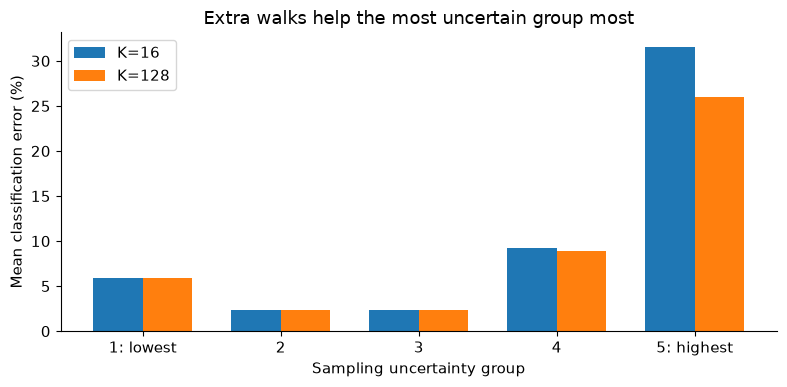

In [8]:
order = np.lexsort((node_ids, U))
groups = np.array_split(order, 5)
rows = []
for q, ix in enumerate(groups, start=1):
    rows.append({'Uncertainty group': q, 'Nodes': len(ix),
                 'Error K=16 (%)': 100 * e16[ix].mean(),
                 'Error K=128 (%)': 100 * e128[ix].mean(),
                 'Benefit (percentage points)': 100 * delta[ix].mean()})
quintiles = pd.DataFrame(rows)
display(quintiles.round(3))

x = np.arange(5)
fig, ax = plt.subplots()
ax.bar(x - .18, quintiles['Error K=16 (%)'], width=.36, label='K=16')
ax.bar(x + .18, quintiles['Error K=128 (%)'], width=.36, label='K=128')
ax.set_xticks(x, ['1: lowest', '2', '3', '4', '5: highest'])
ax.set(xlabel='Sampling uncertainty group', ylabel='Mean classification error (%)',
       title='Extra walks help the most uncertain group most')
ax.legend()
fig.tight_layout()
plt.show()


The highest-uncertainty group falls from **31.59% to 26.02% error**, a **5.57 percentage-point** reduction. The lowest group changes very little.

The top-minus-bottom improvement difference is about **5.54 percentage points**. Its saved node-bootstrap interval is shown below. This supports a benefit association, but the most uncertain nodes are also harder to classify in the first place.

## 6. Experiment B: uncertainty is not the same as being wrong

There are two separate questions:

1. Does uncertainty identify difficult nodes? **Yes, to some extent:** its correlation with K=16 error is about 0.558.
2. Does it identify nodes that improve with more walks? **Also yes in this cache:** its correlation with benefit is about 0.315.

The second question motivates adaptive sampling. Merely detecting difficult nodes would not be enough if those nodes stayed wrong regardless of K.


In [9]:
low, high = groups[0], groups[-1]
low_always_wrong = (e128[low] == 1).mean()
high_improved = (delta[high] > 0).mean()
print(f'Low-uncertainty nodes wrong in all 25 K=128 outcome runs: {100*low_always_wrong:.2f}%')
print(f'High-uncertainty nodes with positive estimated benefit: {100*high_improved:.2f}%')
qdiff = metrics['top_minus_bottom_quintile_delta']
print('Top-minus-bottom group benefit: '
      f"{100*qdiff['estimate']:.2f} percentage points "
      f"(95% interval {100*qdiff['ci95'][0]:.2f} to {100*qdiff['ci95'][1]:.2f})")

# Real cached examples: a stable-but-wrong node and an uncertain node that improves.
examples = [low[np.flatnonzero(e128[low] == 1)[0]],
            high[np.argmax(delta[high])]]
display(pd.DataFrame({
    'Example': ['Low uncertainty, consistently wrong', 'High uncertainty, observed improvement'],
    'Node ID': node_ids[examples], 'True class': labels[examples],
    'Sampling variance': U[examples], 'K=16 error (%)': 100*e16[examples],
    'K=128 error (%)': 100*e128[examples]}))


Low-uncertainty nodes wrong in all 25 K=128 outcome runs: 5.81%
High-uncertainty nodes with positive estimated benefit: 58.36%
Top-minus-bottom group benefit: 5.54 percentage points (95% interval 4.30 to 6.78)


,Example,Node ID,True class,Sampling variance,K=16 error (%),K=128 error (%)
0,"Low uncertainty, consistently wrong",24,4,0.000000,100.0,100.0
1,"High uncertainty, observed improvement",5834,1,0.118087,64.0,16.0


The second example was selected using observed benefit **only to illustrate a real node**, not to construct a policy. Being wrong in every observed run is not proof a node is wrong with probability one.

### Could simpler scores do the same job?

We also compare entropy (how spread out the average probabilities are), negative confidence, negative top-two margin, and variation ratio (how often predictions disagree with their modal class). Every score uses A only and no labels. Higher values mean more uncertain for all five scores.

The table uses the full analysis's saved results. Its first column measures benefit association; the second measures baseline difficulty. Their distinction matters more than picking a winner from tiny differences.


In [10]:
comparison = []
for name, values in metrics['association'].items():
    comparison.append({'Score': name.replace('_', ' '),
                       'Rank correlation with benefit': values['delta_error_spearman']['estimate'],
                       'Rank correlation with baseline error': values['baseline_error_spearman']['estimate']})
display(pd.DataFrame(comparison).round(3))


,Score,Rank correlation with benefit,Rank correlation with baseline error
0,sampling variance,0.315,0.558
1,entropy,0.286,0.622
2,negative confidence,0.283,0.631
3,negative margin,0.281,0.633
4,variation ratio,0.353,0.722


### What if probabilities improve without changing the winning class?

Accuracy only notices whether the top class is correct. We therefore also measure negative log-likelihood (NLL) and Brier score. Both reward better probability estimates; lower is better. NLL penalizes assigning very little probability to the true class. Brier score measures squared distance from the correct one-hot label.

We compute each score separately for each stochastic run, then average. Positive reduction means improvement.


In [11]:
def proper_scores(probabilities, y):
    true_probability = probabilities[:, np.arange(len(y)), y]
    nll = -np.log(np.clip(true_probability, 1e-15, 1)).mean(axis=0)
    brier = ((probabilities ** 2).sum(axis=-1) - 2*true_probability + 1).mean(axis=0)
    return nll, brier

nll16, brier16 = proper_scores(p16_B, labels)
nll128, brier128 = proper_scores(p128_B, labels)
display(pd.DataFrame({'Score': ['NLL', 'Brier'],
                      'K=16': [nll16.mean(), brier16.mean()],
                      'K=128': [nll128.mean(), brier128.mean()],
                      'Reduction': [(nll16-nll128).mean(), (brier16-brier128).mean()]}).round(5))


,Score,K=16,K=128,Reduction
0,NLL,0.34465,0.31252,0.03213
1,Brier,0.15821,0.14164,0.01657


## 7. Experiment C: does the ranking help decide where to spend samples?

This is a retrospective thought experiment, using predictions we already have:

1. Start every node at K=16.
2. Select the most uncertain 25% using **A only**.
3. For selected nodes, use their K=128 error measured on B. Other nodes keep their K=16 error.
4. Compare with choosing a random 25%.

No graph sampling is dynamically changed here. We are stitching together independent outcome estimates to test the ranking's predictive value.

The nominal average budget is 0.75×16 + 0.25×128 = **44**. With 2,751 nodes we select 687, so it is actually 43.97. Fixed K=32 and K=64 bracket this budget; neither is an exactly matched comparison.


Selected 687 nodes; nominal mean K=43.97
Uncertainty allocation error: 9.127%
Random allocation expected error: 9.988%
Mean of 2,000 actual random allocations: 9.988%
Gain over random allocation: 0.861 percentage points


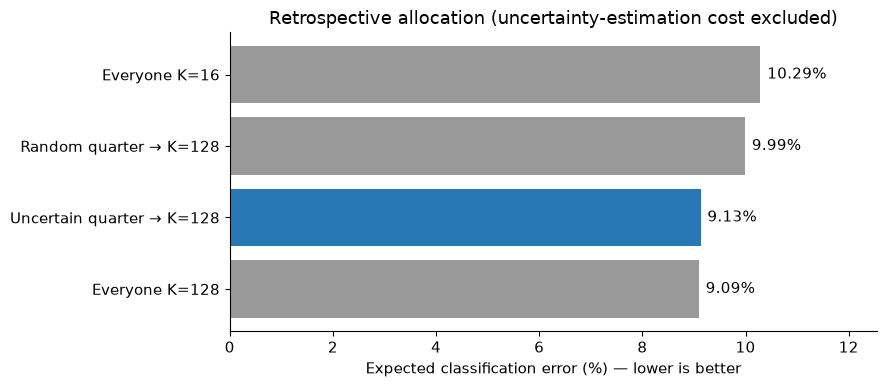

In [12]:
n_selected = len(U) // 4
selected = np.zeros(len(U), dtype=bool)
selected[np.lexsort((node_ids, -U))[:n_selected]] = True
allocation_error = np.where(selected, e128, e16).mean()
fraction = selected.mean()
nominal_budget = 16*(1-fraction) + 128*fraction

# Analytic expected error of uniformly choosing the same number of nodes at random.
random_error = ((1-fraction)*e16 + fraction*e128).mean()
# The full script also evaluates 2,000 random selections; the saved draw mean should agree closely.
random_draw_mean = metrics['policies']['random_25_percent']['allocation_distribution_mean']
print(f'Selected {selected.sum()} nodes; nominal mean K={nominal_budget:.2f}')
print(f'Uncertainty allocation error: {100*allocation_error:.3f}%')
print(f'Random allocation expected error: {100*random_error:.3f}%')
print(f'Mean of 2,000 actual random allocations: {100*random_draw_mean:.3f}%')
print(f'Gain over random allocation: {100*(random_error-allocation_error):.3f} percentage points')

names = ['Everyone K=16', 'Random quarter → K=128', 'Uncertain quarter → K=128', 'Everyone K=128']
errors = 100*np.array([e16.mean(), random_error, allocation_error, e128.mean()])
fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.barh(names, errors, color=['#999999', '#999999', '#2878B5', '#999999'])
ax.invert_yaxis()
ax.set_xlim(0, max(errors)*1.22)
ax.bar_label(bars, labels=[f'{x:.2f}%' for x in errors], padding=5)
ax.set(xlabel='Expected classification error (%) — lower is better',
       title='Retrospective allocation (uncertainty-estimation cost excluded)')
fig.tight_layout()
plt.show()


The uncertainty allocation captures most of the overall K=16→128 error reduction while assigning the larger nominal budget to only a quarter of nodes. Its gain over random selection is **0.86 percentage points**, with a paired node-bootstrap 95% interval of **0.65–1.07**.

**This is not a compute-saving result.** To estimate uncertainty we used 25 runs at K=16: **400 sampled patterns per node**, before the hypothetical allocation. The plot excludes that cost. It would be misleading to claim a practical speedup from a nominal average K of 44. No measured latency was available.

Entropy/confidence/margin allocations also achieve errors around 9.2%; sampling variance is not established as uniquely necessary. A label-informed oracle appears in the full results only as a non-deployable bound: it knows observed benefit and cannot be used at test time.

## 8. What should we conclude?

For this recorded checkpoint, the result is consistent with **case A: uncertainty predicts some benefit from extra walks**. The association, concentration of gains in the highest group, and advantage over random allocation all point in the same direction.

There are limits:

- Uncertainty also tracks baseline difficulty. The study does not prove that uncertainty causes benefit or isolates it from every difficulty-related factor.
- Some low-uncertainty nodes remain consistently wrong. More walks cannot be assumed to solve every model error.
- Outcomes are estimates from 25 runs; individual benefit signs can be noisy.
- The analysis uses one graph and one checkpoint. Node-bootstrap intervals do not establish reproducibility across independently trained models.
- The original checkpoint/masks are missing locally, so the cache's provenance still needs verification before stronger claims.
- No thresholds were tuned on test labels. These are exploratory diagnostic results, not confirmation of a finished adaptive method.

**Next experiment, not implemented:** restore and verify the original model/data, then evaluate a simple validation-calibrated stopping rule that adds walks in batches and checks whether predictions stabilize. Measure actual end-to-end time as well as accuracy, and compare against fixed K and simpler confidence-based rules. Additional trained seeds would strengthen the evidence.

## 9. Reproduce or inspect the detailed analysis

The full script keeps the additional statistical outputs out of this walkthrough: bootstrap intervals, AUROC/AP, all score comparisons, random allocations and proper scoring rules are saved in `results/`.

From the project root:

```sh
python -m unittest discover -s sampling_benefit_diagnostic -v
python sampling_benefit_diagnostic/experiment.py \
  --repository . \
  --cache sampling_experiment_results/computers_sampling_full.npz \
  --output sampling_benefit_diagnostic/results_rerun
```

Use a new output directory to preserve the existing results. Required analysis dependencies are listed in `sampling_benefit_diagnostic/requirements.txt`.
